In [51]:
# Import necessary libraries (same as the professor's FFNN example)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score

import time

# Set random seed for reproducibility
np.random.seed(42)
torch.manual_seed(42)


In [52]:
# ------------------------------------------------------------------------------
# LOAD DATASET
# ------------------------------------------------------------------------------
data = pd.read_csv("dataset_lab_1.csv")
data.columns = data.columns.str.strip()   # remove possible leading spaces in column names

print("Number of rows:", len(data))
data.head()

Number of rows: 31507


,Flow Duration,Flow IAT Mean,Fwd PSH Flags,Bwd Packet Length Mean,Bwd Packet Length Max,Flow Bytes/s,Down/Up Ratio,SYN Flag Count,Fwd Packet Length Mean,Fwd IAT Std,Packet Length Mean,Fwd Packet Length Max,Subflow Fwd Packets,Flow Packets/s,Total Fwd Packets,Destination Port,Label
0,303376,3.03e+04,0,749,1448,1.27e+04,0,0,19.8,9.88e+04,322,119,6,36.3,6,443,Benign
1,117,117,0,0,0,0,1,0,0,0,0,0,1,1.71e+04,1,52631,Benign
2,142,142,0,0,0,8.45e+04,0,0,6,0,6,6,2,1.41e+04,2,80,Benign
3,191,63.7,0,52,52,9.21e+05,1,0,36,0,42.4,36,2,2.09e+04,2,53,Benign
4,4,4,0,0,0,3e+06,0,0,6,0,6,6,2,5e+05,2,49467,Benign


In [60]:
# ------------------------------------------------------------------------------
# INSPECTION
# ------------------------------------------------------------------------------

# Classes and balance
print("\nClass counts:\n", data["Label"].value_counts())
print("\nClass proportions:\n", data["Label"].value_counts(normalize=True))

# Missing values
print("\nNaN per column:\n", data.isna().sum()[data.isna().sum() > 0])

# Infinite values
num = data.drop(columns=["Label"])
inf_per_col = np.isinf(num).sum()
print("\nInf per column:\n", inf_per_col[inf_per_col > 0])

# Duplicates
print("\nDuplicate rows:", data.duplicated().sum())
print("Duplicates by class:\n", data[data.duplicated()]["Label"].value_counts())

# Ranges of the features (to spot implausible values and outliers)
print("\nFeature statistics:\n", num.describe().T[["min", "mean", "max"]])



Class counts:
 Label
0    19242
3     4849
2     3868
1     1427
Name: count, dtype: int64

Class proportions:
 Label
0    0.655
3    0.165
2    0.132
1   0.0486
Name: proportion, dtype: float64

NaN per column:
 Series([], dtype: int64)

Inf per column:
 Series([], dtype: int64)

Duplicate rows: 0
Duplicates by class:
 Series([], Name: count, dtype: int64)

Feature statistics:
                             min     mean      max
Flow Duration                -1 1.77e+07  1.2e+08
Flow IAT Mean                -1 1.54e+06 1.14e+08
Fwd PSH Flags                 0   0.0394        1
Bwd Packet Length Mean        0      332 3.86e+03
Bwd Packet Length Max         0      960 1.16e+04
Flow Bytes/s           -1.2e+07 1.44e+06 2.07e+09
Down/Up Ratio                 0    0.666       10
SYN Flag Count                0   0.0394        1
Fwd Packet Length Mean        0     46.8 3.43e+03
Fwd IAT Std                   0 4.99e+06 8.28e+07
Packet Length Mean            0      174  1.9e+03
Fwd Packet Length

In [54]:
# ------------------------------------------------------------------------------
# PREPROCESSING
# ------------------------------------------------------------------------------

# Treat inf as missing values
data = data.replace([np.inf, -np.inf], np.nan)

# Remove duplicates
print("\nNumber of rows before duplicates", len(data))
data = data.drop_duplicates()
print("Number of rows after duplicates", len(data))

# Remove rows with missing values
data = data.dropna()
print("Number of rows after missing values", len(data))

print("\nClass counts after cleaning:\n", data["Label"].value_counts())

# Encode labels
label_encoder = LabelEncoder()
data["Label"] = label_encoder.fit_transform(data["Label"])
print("\nEncoding:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))



Number of rows before duplicates 31507
Number of rows after duplicates 29396
Number of rows after missing values 29386

Class counts after cleaning:
 Label
Benign         19242
PortScan        4849
DoS Hulk        3868
Brute Force     1427
Name: count, dtype: int64

Encoding: {'Benign': 0, 'Brute Force': 1, 'DoS Hulk': 2, 'PortScan': 3}


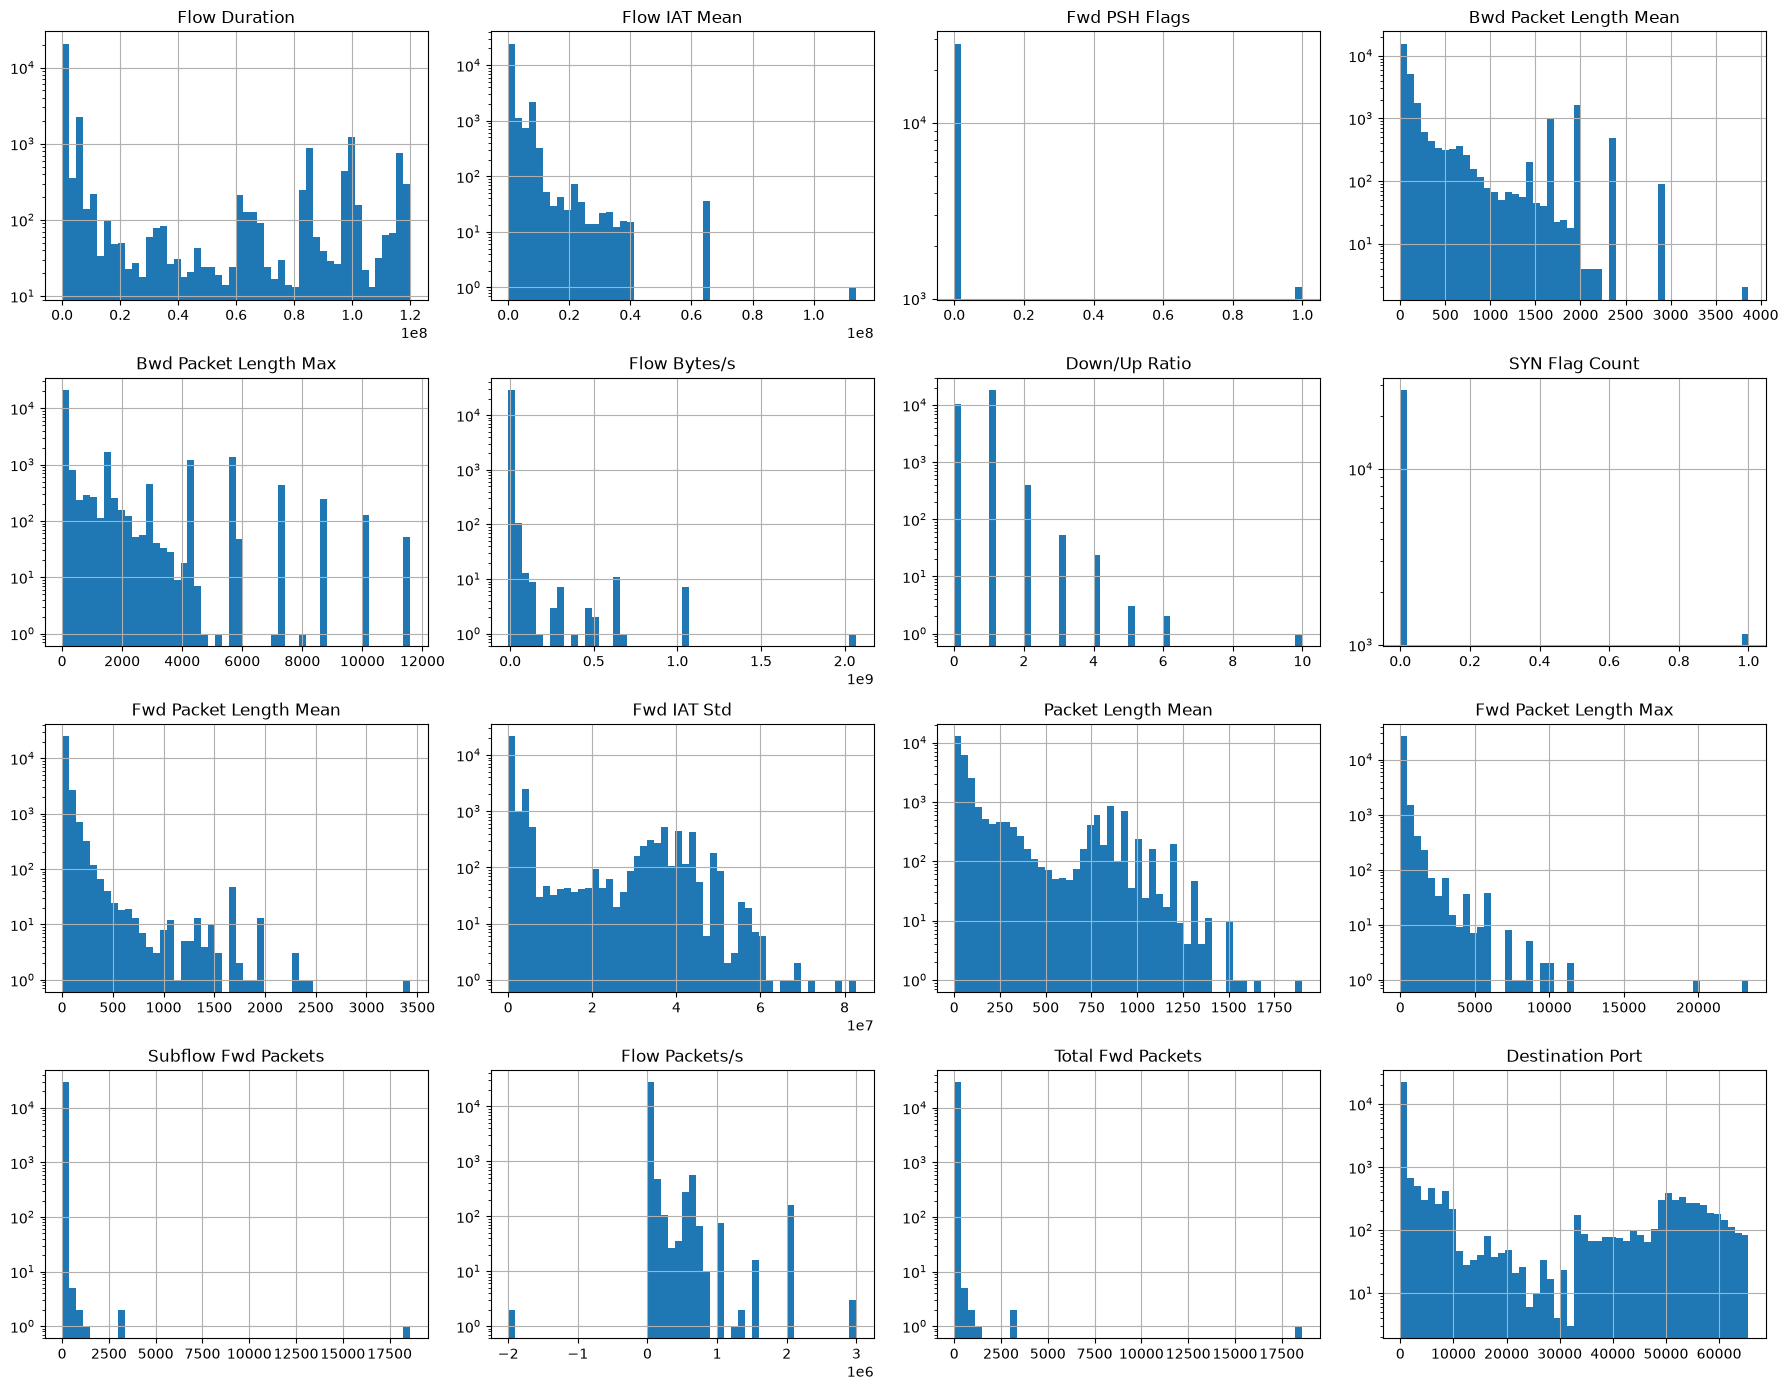

In [55]:
# ------------------------------------------------------------------------------
# DATA VISUALIZATION
# ------------------------------------------------------------------------------

# Too many features for a scatter plot: histograms of each feature instead
data.drop(columns=["Label"]).hist(bins=50, figsize=(18, 14), log=True)
plt.tight_layout()
plt.show()
plt.close()

In [56]:
# ------------------------------------------------------------------------------
# SPLITTING
# ------------------------------------------------------------------------------

feature_names = data.drop(columns=["Label"]).columns.tolist()
X = data[feature_names].values
y = data["Label"].values

# stratify=y keeps the same class proportions in every partition (imbalanced classes)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

for name, yy in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"\n{name}: {len(yy)} rows")
    print(pd.Series(label_encoder.inverse_transform(yy)).value_counts(normalize=True))


train: 20570 rows
Benign         0.655
PortScan       0.165
DoS Hulk       0.132
Brute Force   0.0486
Name: proportion, dtype: float64

val: 4408 rows
Benign         0.655
PortScan       0.165
DoS Hulk       0.132
Brute Force   0.0485
Name: proportion, dtype: float64

test: 4408 rows
Benign         0.655
PortScan       0.165
DoS Hulk       0.132
Brute Force   0.0485
Name: proportion, dtype: float64


In [57]:
# ------------------------------------------------------------------------------
# STANDARDIZATION
# ------------------------------------------------------------------------------
# Fit ONLY on the training set, then apply to validation and test
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [58]:
# ------------------------------------------------------------------------------
# TENSORS
# ------------------------------------------------------------------------------

X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

In [59]:
#